# TRAINING BEGIN

In [ ]:
#cell 1
from pathlib import Path
from PIL import Image, ImageOps
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

dataset_path = Path(
    r"C:\Users\saman\OneDrive\Desktop\OG flower dataset\archive\102 flower"
)

flowers_path = dataset_path / "flowers"
train_path = flowers_path / "train"
valid_path = flowers_path / "valid"
test_path = flowers_path / "test"

class ResizeAndPad:

    def __init__(self, size):
        self.size = size

    def __call__(self, image):

        width, height = image.size

        scale = min(self.size / width, self.size / height)

        new_width = int(width * scale)
        new_height = int(height * scale)

        image = image.resize(
            (new_width, new_height),
            Image.Resampling.LANCZOS
        )

        left = (self.size - new_width) // 2
        right = self.size - new_width - left
        top = (self.size - new_height) // 2
        bottom = self.size - new_height - top

        image = ImageOps.expand(
            image,
            border=(left, top, right, bottom),
            fill="black"
        )

        return image


resize_and_pad = ResizeAndPad(224)


train_transforms = transforms.Compose([
    transforms.Lambda(resize_and_pad),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

valid_test_transforms = transforms.Compose([
    transforms.Lambda(resize_and_pad),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


train_dataset = datasets.ImageFolder(
    train_path,
    transform=train_transforms
)

valid_dataset = datasets.ImageFolder(
    valid_path,
    transform=valid_test_transforms
)

test_dataset = datasets.ImageFolder(
    test_path,
    transform=valid_test_transforms
)


batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)


print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Testing images:", len(test_dataset))

Training images: 6552
Validation images: 818
Testing images: 819


In [ ]:
#cell 2
from torchvision import models
import torch

resnet50 = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

resnet50.fc = torch.nn.Linear(
    resnet50.fc.in_features,
    102
)

print("ResNet-50 model loaded successfully.")

ResNet-50 model loaded successfully.


In [ ]:
#cell 3
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cpu


In [ ]:
#cell 4
resnet50 = resnet50.to(device)

num_epochs = 3

print("Device:", device)
print("Number of epochs:", num_epochs)
print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))

Device: cpu
Number of epochs: 3
Training images: 6552
Validation images: 818


In [ ]:
#cell 5
###freezes pretrained ResNet-50 layers

for parameter in resnet50.parameters():
    parameter.requires_grad = False

for parameter in resnet50.fc.parameters():
    parameter.requires_grad = True

resnet50 = resnet50.to(device)


In [ ]:
#cell 6
criterion = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    resnet50.fc.parameters(),
    lr=0.001
)

print("Loss function and optimizer are ready.")

Loss function and optimizer are ready.


In [ ]:
#cell 7
print("Device:", device)
print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Testing images:", len(test_dataset))

print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))

print("Output classes:", resnet50.fc.out_features)

trainable_parameters = sum(
    parameter.numel()
    for parameter in resnet50.parameters()
    if parameter.requires_grad
)

print("Trainable parameters:", trainable_parameters)

Device: cpu
Training images: 6552
Validation images: 818
Testing images: 819
Training batches: 205
Validation batches: 26
Output classes: 102
Trainable parameters: 208998


In [ ]:
#cell 8
#  3 epochs
#### TRAINING
for epoch in range(num_epochs):

    resnet50.train()

    for module in resnet50.modules():
        if isinstance(module, torch.nn.BatchNorm2d):
            module.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet50(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Training Loss: {epoch_loss:.4f} "
        f"Training Accuracy: {epoch_accuracy:.2f}%"
    )

Epoch [1/3] Training Loss: 4.5865 Training Accuracy: 3.48%
Epoch [2/3] Training Loss: 4.4742 Training Accuracy: 8.00%
Epoch [3/3] Training Loss: 4.3846 Training Accuracy: 8.39%


In [ ]:
#cell 9

##### VALIDATION

resnet50.eval()

valid_loss = 0.0
correct = 0
total = 0

with torch.no_grad():

    for images, labels in valid_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet50(images)

        loss = criterion(outputs, labels)

        valid_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

valid_loss = valid_loss / total
valid_accuracy = 100 * correct / total

print("Validation Loss:", round(valid_loss, 4))
print("Validation Accuracy:", round(valid_accuracy, 2), "%")

Validation Loss: 4.3636
Validation Accuracy: 10.02 %


In [ ]:
#cell 10
print("Training classes match validation classes:",
      train_dataset.class_to_idx == valid_dataset.class_to_idx)

print("Number of training classes:", len(train_dataset.classes))
print("Number of validation classes:", len(valid_dataset.classes))

print("First 10 training classes:", train_dataset.classes[:10])
print("First 10 validation classes:", valid_dataset.classes[:10])

Training classes match validation classes: True
Number of training classes: 102
Number of validation classes: 102
First 10 training classes: ['1', '10', '100', '101', '102', '11', '12', '13', '14', '15']
First 10 validation classes: ['1', '10', '100', '101', '102', '11', '12', '13', '14', '15']


In [ ]:
#cell 11
###### New ResNet-50 experiment

from torchvision import models

resnet50 = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

resnet50.fc = torch.nn.Linear(
    resnet50.fc.in_features,
    102
)

for parameter in resnet50.parameters():
    parameter.requires_grad = False

for parameter in resnet50.fc.parameters():
    parameter.requires_grad = True

resnet50 = resnet50.to(device)

criterion = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    resnet50.fc.parameters(),
    lr=0.001
)

num_epochs = 3

print("Fresh ResNet-50 model is ready.")
print("Device:", device)
print("Trainable parameters:", sum(
    parameter.numel()
    for parameter in resnet50.parameters()
    if parameter.requires_grad
))

Fresh ResNet-50 model is ready.
Device: cpu
Trainable parameters: 208998


In [ ]:

#cell 12

for epoch in range(num_epochs):

    resnet50.train()

    for module in resnet50.modules():
        if isinstance(module, torch.nn.BatchNorm2d):
            module.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet50(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    print(f"Epoch [{epoch + 1}/{num_epochs}]")
    print(f"Training Loss: {epoch_loss:.4f}")
    print(f"Training Accuracy: {epoch_accuracy:.2f}%")

Epoch [1/3]
Training Loss: 4.5744
Training Accuracy: 4.40%
Epoch [2/3]
Training Loss: 4.4669
Training Accuracy: 6.94%
Epoch [3/3]
Training Loss: 4.3782
Training Accuracy: 7.80%


In [ ]:
#cell 13

resnet50.eval()

valid_loss = 0.0
correct = 0
total = 0

with torch.no_grad():

    for images, labels in valid_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet50(images)
        loss = criterion(outputs, labels)

        valid_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

valid_loss = valid_loss / total
valid_accuracy = 100 * correct / total

print("Validation Loss:", round(valid_loss, 4))
print("Validation Accuracy:", round(valid_accuracy, 2), "%")

Validation Loss: 4.3519
Validation Accuracy: 9.41 %


In [ ]:
#Cell 14
##### change learning rate from 0.001 to 0.01

from torchvision import models

resnet50 = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

resnet50.fc = torch.nn.Linear(
    resnet50.fc.in_features,
    102
)

for parameter in resnet50.parameters():
    parameter.requires_grad = False

for parameter in resnet50.fc.parameters():
    parameter.requires_grad = True

resnet50 = resnet50.to(device)

criterion = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    resnet50.fc.parameters(),
    lr=0.01
)

num_epochs = 3

print("Learning rate:", 0.01)
print("Trainable parameters:", sum(
    parameter.numel()
    for parameter in resnet50.parameters()
    if parameter.requires_grad
))

Learning rate: 0.01
Trainable parameters: 208998


In [ ]:
#cell 15
##### 0.01 learning rate

for epoch in range(num_epochs):

    resnet50.train()

    for module in resnet50.modules():
        if isinstance(module, torch.nn.BatchNorm2d):
            module.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet50(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    print("Epoch [{}/{}]".format(epoch + 1, num_epochs))
    print("Training Loss:", round(epoch_loss, 4))
    print("Training Accuracy:", round(epoch_accuracy, 2), "%")
    print()

Epoch [1/3]
Training Loss: 4.252
Training Accuracy: 10.42 %

Epoch [2/3]
Training Loss: 3.7476
Training Accuracy: 22.28 %

Epoch [3/3]
Training Loss: 3.3687
Training Accuracy: 32.14 %



In [ ]:
#cell 16
resnet50.eval()

valid_loss = 0.0
correct = 0
total = 0

with torch.no_grad():

    for images, labels in valid_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet50(images)
        loss = criterion(outputs, labels)

        valid_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

valid_loss = valid_loss / total
valid_accuracy = 100 * correct / total

print("Validation Loss:", round(valid_loss, 4))
print("Validation Accuracy:", round(valid_accuracy, 2), "%")

Validation Loss: 3.297
Validation Accuracy: 35.94 %


In [ ]:
#cell 17
torch.save(
    resnet50.state_dict(),
    "resnet50_frozen_lr_001.pth"
)


for parameter in resnet50.parameters():
    parameter.requires_grad = False


for parameter in resnet50.layer4.parameters():
    parameter.requires_grad = True

for parameter in resnet50.fc.parameters():
    parameter.requires_grad = True

optimizer = torch.optim.SGD(
    [
        {"params": resnet50.layer4.parameters(), "lr": 0.0001},
        {"params": resnet50.fc.parameters(), "lr": 0.01}
    ]
)

num_epochs = 3

print("Fine-tuning model is ready.")
print("Trainable parameters:", sum(
    parameter.numel()
    for parameter in resnet50.parameters()
    if parameter.requires_grad
))

Fine-tuning model is ready.
Trainable parameters: 15173734


In [ ]:
#cell 18
### Fine tuned version
for epoch in range(num_epochs):

    resnet50.train()

    for module in resnet50.modules():
        if isinstance(module, torch.nn.BatchNorm2d):
            if not any(parameter.requires_grad for parameter in module.parameters()):
                module.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet50(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    print("Epoch [{}/{}]".format(epoch + 1, num_epochs))
    print("Training Loss:", round(epoch_loss, 4))
    print("Training Accuracy:", round(epoch_accuracy, 2), "%")
    print()

Epoch [1/3]
Training Loss: 3.9099
Training Accuracy: 31.87 %

Epoch [2/3]
Training Loss: 3.5881
Training Accuracy: 36.4 %

Epoch [3/3]
Training Loss: 3.2842
Training Accuracy: 41.16 %



In [ ]:
#cell 19
resnet50.eval()

valid_loss = 0.0
correct = 0
total = 0

with torch.no_grad():

    for images, labels in valid_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet50(images)

        loss = criterion(outputs, labels)

        valid_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

valid_loss = valid_loss / total
valid_accuracy = 100 * correct / total

print("Validation Loss:", round(valid_loss, 4))
print("Validation Accuracy:", round(valid_accuracy, 2), "%")

Validation Loss: 3.2727
Validation Accuracy: 42.18 %


In [ ]:
#cell 20
### Save 

torch.save(
    resnet50.state_dict(),
    "resnet50_finetuned_layer4.pth"
)

print("Fine-tuned model saved successfully.")

Fine-tuned model saved successfully.


In [ ]:
#cell 21
# Final evaluation using test dataset

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

resnet50.load_state_dict(
    torch.load("resnet50_finetuned_layer4.pth", map_location=device)
)

resnet50.eval()

test_loss = 0.0
total = 0

all_labels = []
all_predictions = []

with torch.no_grad():

    for batch_number, (images, labels) in enumerate(test_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet50(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

        print("Completed batch:", batch_number + 1, "of", len(test_loader))


test_loss = test_loss / total

test_accuracy = accuracy_score(all_labels, all_predictions)
test_precision = precision_score(all_labels, all_predictions, average="weighted", zero_division=0)
test_recall = recall_score(all_labels, all_predictions, average="weighted", zero_division=0)
test_f1 = f1_score(all_labels, all_predictions, average="weighted", zero_division=0)

print("\nFINAL TEST RESULTS")
print("------------------------")
print("Test Images:", total)
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Precision:", round(test_precision, 4))
print("Recall:", round(test_recall, 4))
print("F1-Score:", round(test_f1, 4))

Completed batch: 1 of 26
Completed batch: 2 of 26
Completed batch: 3 of 26
Completed batch: 4 of 26
Completed batch: 5 of 26
Completed batch: 6 of 26
Completed batch: 7 of 26
Completed batch: 8 of 26
Completed batch: 9 of 26
Completed batch: 10 of 26
Completed batch: 11 of 26
Completed batch: 12 of 26
Completed batch: 13 of 26
Completed batch: 14 of 26
Completed batch: 15 of 26
Completed batch: 16 of 26
Completed batch: 17 of 26
Completed batch: 18 of 26
Completed batch: 19 of 26
Completed batch: 20 of 26
Completed batch: 21 of 26
Completed batch: 22 of 26
Completed batch: 23 of 26
Completed batch: 24 of 26
Completed batch: 25 of 26
Completed batch: 26 of 26

FINAL TEST RESULTS
------------------------
Test Images: 819
Test Loss: 3.3026
Test Accuracy: 40.66 %
Precision: 0.3697
Recall: 0.4066
F1-Score: 0.323


<Figure size 1800x1800 with 0 Axes>

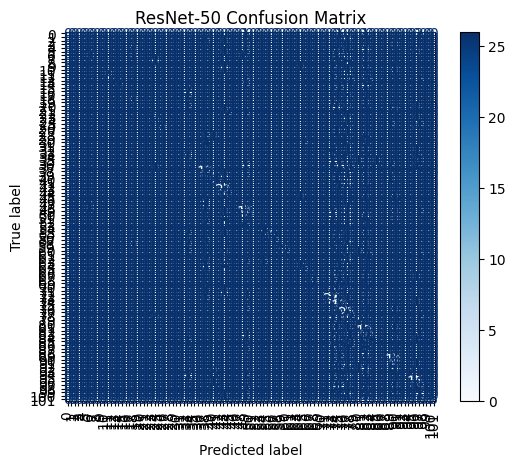

In [ ]:
#cell 22
### confusion matrix

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(18, 18))

disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot(
    cmap="Blues",
    xticks_rotation="vertical",
    values_format="d"
)

plt.title("ResNet-50 Confusion Matrix")
plt.show()

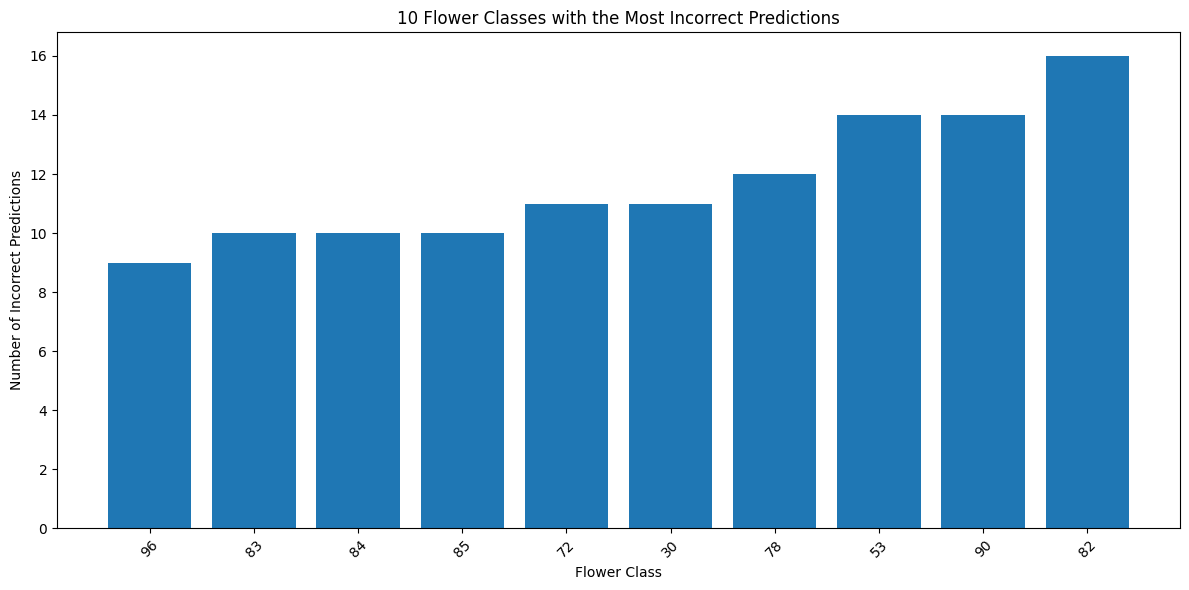

In [ ]:
#Cell 23
# Find the 10 classes with the most incorrect predictions

import numpy as np
import matplotlib.pyplot as plt

incorrect_predictions = cm.sum(axis=1) - np.diag(cm)

top_10 = np.argsort(incorrect_predictions)[-10:]

plt.figure(figsize=(12, 6))

plt.bar(
    [test_dataset.classes[i] for i in top_10],
    incorrect_predictions[top_10]
)

plt.title("10 Flower Classes with the Most Incorrect Predictions")
plt.xlabel("Flower Class")
plt.ylabel("Number of Incorrect Predictions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#Cell 24
# Find the most common incorrect predictions

errors = []

for actual in range(len(test_dataset.classes)):
    for predicted in range(len(test_dataset.classes)):

        if actual != predicted and cm[actual, predicted] > 0:

            errors.append((
                test_dataset.classes[actual],
                test_dataset.classes[predicted],
                cm[actual, predicted]
            ))

errors.sort(key=lambda x: x[2], reverse=True)

print("Top 10 Most Common Classification Errors")
print("------------------------------------------")

for error in errors[:10]:
    print(
        "Actual:", error[0],
        "| Predicted:", error[1],
        "| Errors:", error[2]
    )

Top 10 Most Common Classification Errors
------------------------------------------
Actual: 82 | Predicted: 77 | Errors: 11
Actual: 30 | Predicted: 77 | Errors: 8
Actual: 33 | Predicted: 77 | Errors: 8
Actual: 100 | Predicted: 41 | Errors: 6
Actual: 35 | Predicted: 77 | Errors: 6
Actual: 38 | Predicted: 77 | Errors: 6
Actual: 55 | Predicted: 51 | Errors: 6
Actual: 7 | Predicted: 81 | Errors: 6
Actual: 90 | Predicted: 89 | Errors: 6
Actual: 92 | Predicted: 77 | Errors: 6


In [ ]:
#Cell 25
# Display the top 10 errors with flower names

for actual_folder, predicted_folder, count in errors[:10]:

    print(
        "Actual:", cat_to_name[actual_folder],
        "| Predicted:", cat_to_name[predicted_folder],
        "| Errors:", count
    )

Actual: clematis | Predicted: passion flower | Errors: 11
Actual: sweet william | Predicted: passion flower | Errors: 8
Actual: love in the mist | Predicted: passion flower | Errors: 8
Actual: blanket flower | Predicted: barbeton daisy | Errors: 6
Actual: alpine sea holly | Predicted: passion flower | Errors: 6
Actual: great masterwort | Predicted: passion flower | Errors: 6
Actual: pelargonium | Predicted: petunia | Errors: 6
Actual: moon orchid | Predicted: frangipani | Errors: 6
Actual: canna lily | Predicted: watercress | Errors: 6
Actual: bee balm | Predicted: passion flower | Errors: 6


Actual: clematis
Predicted: passion flower
Number of errors: 11


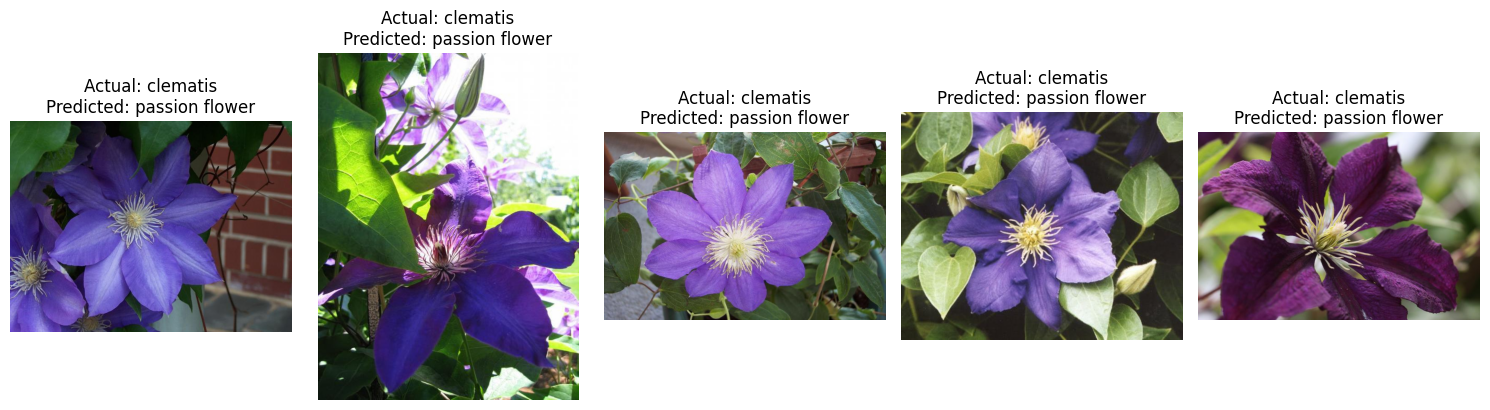

In [ ]:
#Cell 26
#  misclassified 

from PIL import Image
import matplotlib.pyplot as plt

actual_folder, predicted_folder, count = errors[0]

actual_index = test_dataset.class_to_idx[actual_folder]
predicted_index = test_dataset.class_to_idx[predicted_folder]

wrong_indices = []

for i in range(len(all_labels)):
    if all_labels[i] == actual_index and all_predictions[i] == predicted_index:
        wrong_indices.append(i)

print("Actual:", cat_to_name[actual_folder])
print("Predicted:", cat_to_name[predicted_folder])
print("Number of errors:", len(wrong_indices))

plt.figure(figsize=(15, 4))

for i in range(min(5, len(wrong_indices))):

    image_path = test_dataset.samples[wrong_indices[i]][0]
    image = Image.open(image_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        "Actual: " + cat_to_name[actual_folder] +
        "\nPredicted: " + cat_to_name[predicted_folder]
    )

plt.tight_layout()
plt.show()

Actual: sweet william
Predicted: passion flower
Number of errors: 8


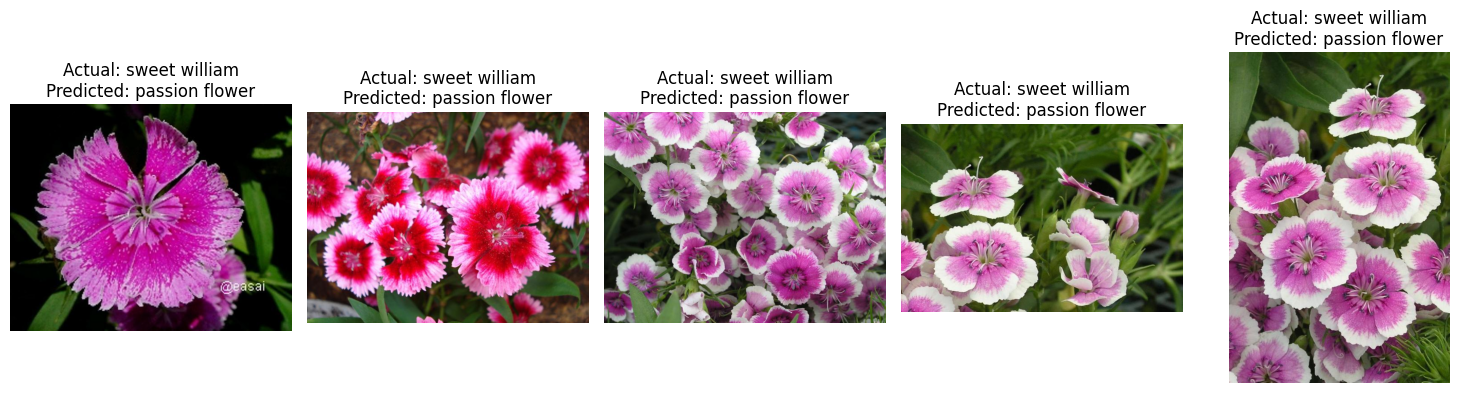

In [ ]:
#27
#  misclassified 

from PIL import Image
import matplotlib.pyplot as plt

actual_folder, predicted_folder, count = errors[1]

actual_index = test_dataset.class_to_idx[actual_folder]
predicted_index = test_dataset.class_to_idx[predicted_folder]

wrong_indices = []

for i in range(len(all_labels)):
    if all_labels[i] == actual_index and all_predictions[i] == predicted_index:
        wrong_indices.append(i)

print("Actual:", cat_to_name[actual_folder])
print("Predicted:", cat_to_name[predicted_folder])
print("Number of errors:", len(wrong_indices))

plt.figure(figsize=(15, 4))

for i in range(min(5, len(wrong_indices))):

    image_path = test_dataset.samples[wrong_indices[i]][0]
    image = Image.open(image_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        "Actual: " + cat_to_name[actual_folder] +
        "\nPredicted: " + cat_to_name[predicted_folder]
    )

plt.tight_layout()
plt.show()

Actual: love in the mist
Predicted: passion flower
Number of errors: 8


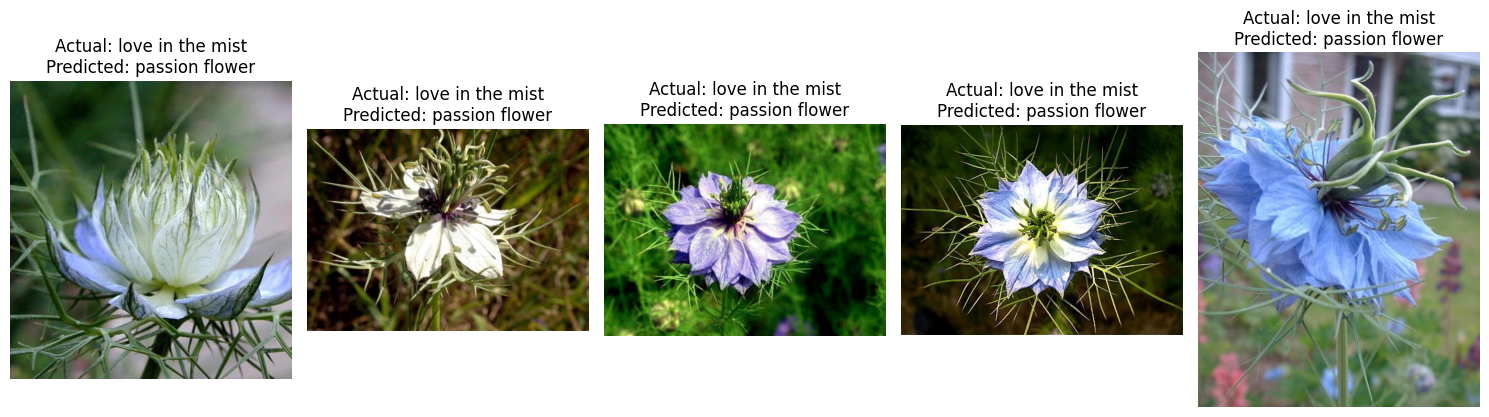

In [ ]:
#28
# misclassified 

from PIL import Image
import matplotlib.pyplot as plt

actual_folder, predicted_folder, count = errors[2]

actual_index = test_dataset.class_to_idx[actual_folder]
predicted_index = test_dataset.class_to_idx[predicted_folder]

wrong_indices = []

for i in range(len(all_labels)):
    if all_labels[i] == actual_index and all_predictions[i] == predicted_index:
        wrong_indices.append(i)

print("Actual:", cat_to_name[actual_folder])
print("Predicted:", cat_to_name[predicted_folder])
print("Number of errors:", len(wrong_indices))

plt.figure(figsize=(15, 4))

for i in range(min(5, len(wrong_indices))):

    image_path = test_dataset.samples[wrong_indices[i]][0]
    image = Image.open(image_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        "Actual: " + cat_to_name[actual_folder] +
        "\nPredicted: " + cat_to_name[predicted_folder]
    )

plt.tight_layout()
plt.show()

In [ ]:
#29
# Final results

print("FINAL RESNET-50 RESULTS")
print("------------------------------")

print("Validation Accuracy: 42.18%")
print("Test Accuracy: 40.66%")
print("Weighted Precision: 0.3697")
print("Weighted Recall: 0.4066")
print("Weighted F1-Score: 0.3230")

print("\nValidation-Test Accuracy Difference: 1.52 percentage points")

FINAL RESNET-50 RESULTS
------------------------------
Validation Accuracy: 42.18%
Test Accuracy: 40.66%
Weighted Precision: 0.3697
Weighted Recall: 0.4066
Weighted F1-Score: 0.3230

Validation-Test Accuracy Difference: 1.52 percentage points
